Create sociograms for the persons-by-persons network and the committee-by committee
network for a given relevant problem. Create one-mode network and two-node network
for the same. For example:
Eight employees at a small company were asked to choose 3 movies that they would
most enjoy watching for the upcoming company movie night. These choices are stored
in the file Employee_Movie_Choices.txt.
Both files are tab delimited.
Load in the bipartite graph from Employee_Movie_Choices.txt and return that graph.

expected output:
Graph


In [ ]:
with open("Emp.txt", "r", encoding="utf-8") as file:
    text=file.readlines()
    for line in text:
        print(line)

Atiya	DDLJ

Atiya	YJHD

Atiya	TALBILB

Anushka	KG		

Anushka	JWM

Anushka	TALBILB

Ankita	HNY

Ankita	YJHD

Ankita	KG

Heena	TALBILB

Heena	YJHD

Heena	RV

Niriksha	YJHD

Niriksha	JWM

Niriksha	DDLJ	

Aayushi	HNY

Aayushi	YJHD

Aayushi	KG

Kanak	DDLJ

Kanak	RV

Kanak	JWM

Aneeza	RV

Aneeza	ncdaoc

Aneeza	JWM



In [ ]:
#TWO-MODE NETWORK
adj_list_1 = {}
adj_list_2={}
emp = []
mov = []

for line in text:
    parts = line.split('\t')

    current_emp = parts[0]
    current_mov = parts[1].strip('\n')

    emp.append(current_emp)
    mov.append(current_mov)

    if current_emp not in adj_list_1:
        adj_list_1[current_emp] = []
    if current_mov not in adj_list_2:
      adj_list_2[current_mov] = []

    adj_list_1[current_emp].append(current_mov)
    adj_list_2[current_mov].append(current_emp)

print("\nTWO-MODE Network ")
print("\nEMP->MOVIE")
for key,value in adj_list_1.items():
  print(f"\n{key} : {value}")
print("\nMovie->Emp")
for key,value in adj_list_2.items():
  print(f"\n{key} : {value}")



TWO-MODE Network 

EMP->MOVIE

Atiya : ['DDLJ', 'YJHD', 'TALBILB']

Anushka : ['KG', 'JWM', 'TALBILB']

Ankita : ['HNY', 'YJHD', 'KG']

Heena : ['TALBILB', 'YJHD', 'RV']

Niriksha : ['YJHD', 'JWM', 'DDLJ']

Aayushi : ['HNY', 'YJHD', 'KG']

Kanak : ['DDLJ', 'RV', 'JWM']

Aneeza : ['RV', 'ncdaoc', 'JWM']

Movie->Emp

DDLJ : ['Atiya', 'Niriksha', 'Kanak']

YJHD : ['Atiya', 'Ankita', 'Heena', 'Niriksha', 'Aayushi']

TALBILB : ['Atiya', 'Anushka', 'Heena']

KG : ['Anushka', 'Ankita', 'Aayushi']

JWM : ['Anushka', 'Niriksha', 'Kanak', 'Aneeza']

HNY : ['Ankita', 'Aayushi']

RV : ['Heena', 'Kanak', 'Aneeza']

ncdaoc : ['Aneeza']


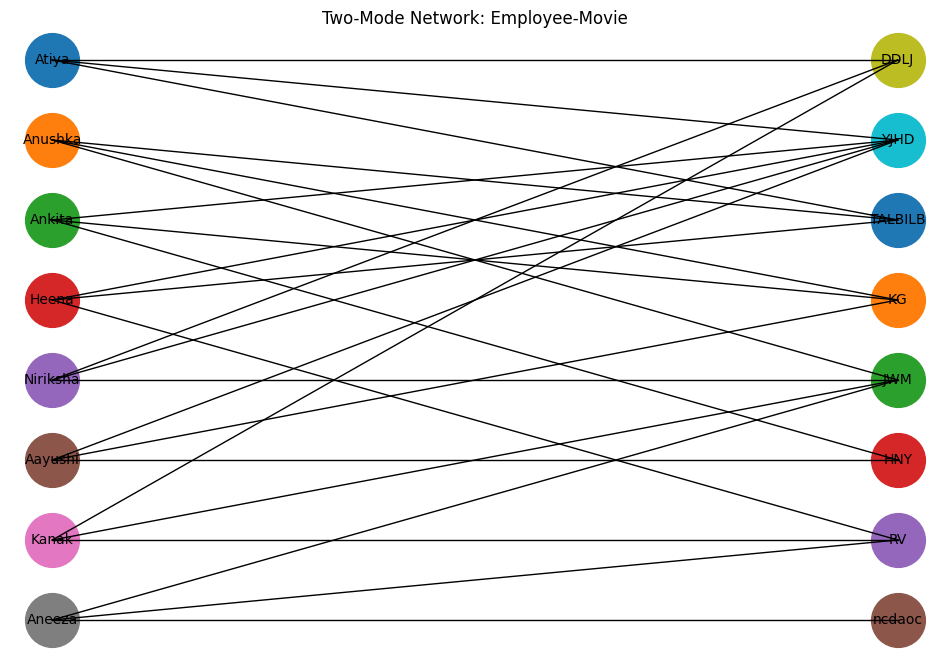

In [ ]:
import matplotlib.pyplot as plt
# TWO-MODE NETWORK Employee - Movie

plt.figure(figsize=(12, 8))

employees = list(adj_list_1.keys())
movies = list(adj_list_2.keys())

emp_pos = {}
movie_pos = {}

for i, employee in enumerate(employees):
    emp_pos[employee] = (1, len(employees) - i)

for i, movie in enumerate(movies):
    movie_pos[movie] = (5, len(movies) - i)

for employee in adj_list_1:
    for movie in adj_list_1[employee]:
        x1, y1 = emp_pos[employee]
        x2, y2 = movie_pos[movie]
        plt.plot([x1, x2],[y1, y2],'k-',linewidth=1)
for employee in employees:
    x, y = emp_pos[employee]
    plt.scatter(x,y,s=1500)
    plt.text(x,y,employee,ha='center',va='center')


for movie in movies:
    x, y = movie_pos[movie]
    plt.scatter(x,y,s=1500)
    plt.text(x,y,movie,ha='center',va='center')
plt.title("Two-Mode Network: Employee-Movie")
plt.axis("off")
plt.show()

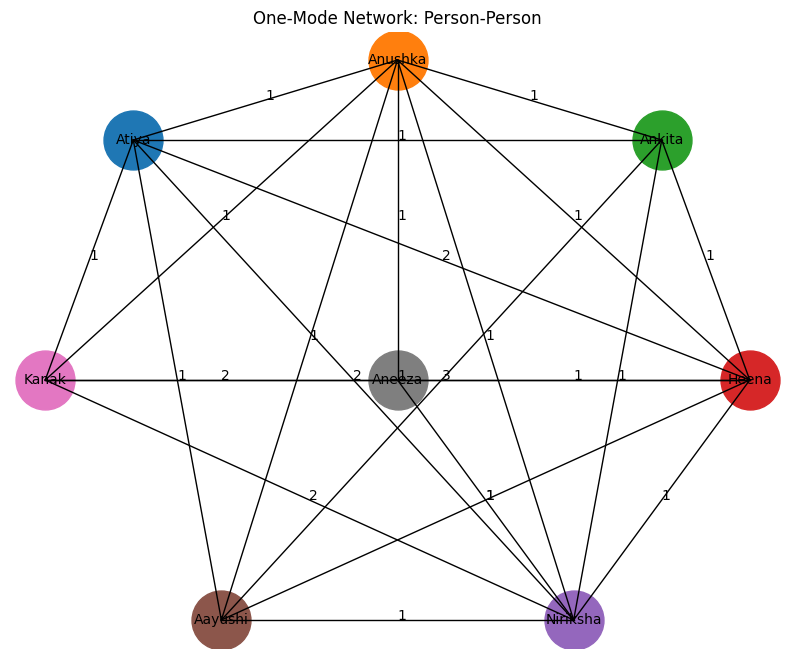

In [ ]:
# ONE-MODE NETWORK
# Person - Person
plt.figure(figsize=(10, 8))
employees = list(adj_list_1.keys())
pos = {}
pos["Atiya"] = (2, 7)
pos["Anushka"] = (5, 8)
pos["Ankita"] = (8, 7)
pos["Heena"] = (9, 4)
pos["Niriksha"] = (7, 1)
pos["Aayushi"] = (3, 1)
pos["Kanak"] = (1, 4)
pos["Aneeza"] = (5, 4)

for i in range(len(employees)):
    for j in range(i + 1, len(employees)):
        emp1 = employees[i]
        emp2 = employees[j]
        common_movies = set(adj_list_1[emp1]) & set(adj_list_1[emp2])
        if len(common_movies) > 0:
            x1, y1 = pos[emp1]
            x2, y2 = pos[emp2]
            plt.plot([x1, x2],[y1, y2],'k-',linewidth=1)
            mid_x = (x1 + x2) / 2
            mid_y = (y1 + y2) / 2
            plt.text(mid_x,mid_y,str(len(common_movies)),fontsize=10)

for employee in employees:
    x, y = pos[employee]
    plt.scatter(x,y,s=1800)
    plt.text(x,y,employee,ha='center',va='center')
plt.title("One-Mode Network: Person-Person")
plt.axis("off")
plt.show()

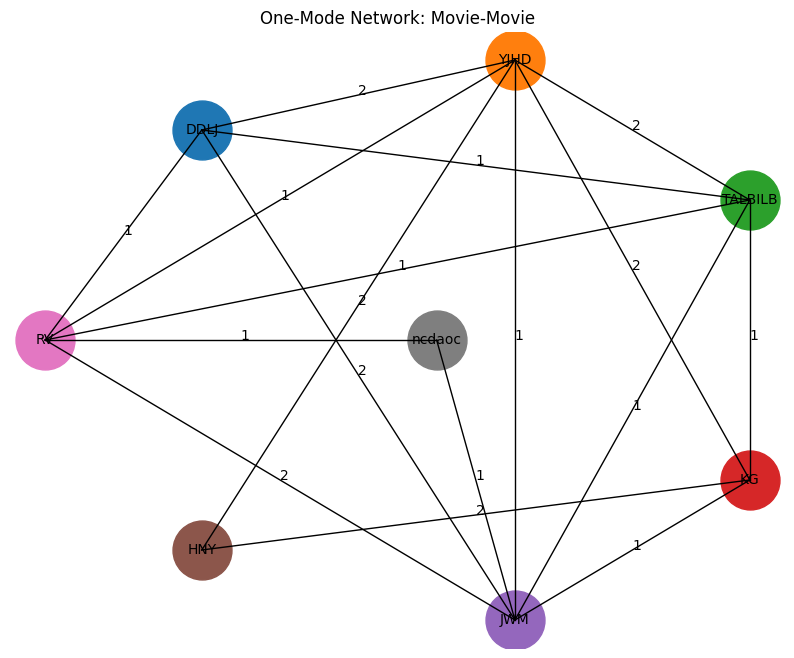

In [ ]:
# ONE-MODE NETWORK Movie - Movie
plt.figure(figsize=(10, 8))
movies = list(adj_list_2.keys())
pos = {}

pos["DDLJ"] = (2, 7)
pos["YJHD"] = (6, 8)
pos["TALBILB"] = (9, 6)
pos["KG"] = (9, 2)
pos["JWM"] = (6, 0)
pos["HNY"] = (2, 1)
pos["RV"] = (0, 4)
pos["ncdaoc"] = (5, 4)

for i in range(len(movies)):
    for j in range(i + 1, len(movies)):
        movie1 = movies[i]
        movie2 = movies[j]
        common_employees = set(adj_list_2[movie1]) & set(adj_list_2[movie2])
        if len(common_employees) > 0:
            x1, y1 = pos[movie1]
            x2, y2 = pos[movie2]
            plt.plot([x1, x2],[y1, y2],'k-',linewidth=1)

            mid_x = (x1 + x2) / 2
            mid_y = (y1 + y2) / 2

            plt.text(mid_x,mid_y,str(len(common_employees)),fontsize=10)

for movie in movies:
    x, y = pos[movie]
    plt.scatter(x,y,s=1800)
    plt.text(x,y,movie,ha='center',va='center')

plt.title("One-Mode Network: Movie-Movie")
plt.axis("off")
plt.show()

In [ ]:
#Practical 7
graph = adj_list_1
node_attributes = {}

for employee in graph:
    node_attributes[employee] = {
        'type': 'employee'
    }

for employee in graph:
    for movie in graph[employee]:
        if movie not in node_attributes:
            node_attributes[movie] = {
                'type': 'movie'
            }

for node in node_attributes:
    print(node, "->", node_attributes[node])

Atiya -> {'type': 'employee'}
Anushka -> {'type': 'employee'}
Ankita -> {'type': 'employee'}
Heena -> {'type': 'employee'}
Niriksha -> {'type': 'employee'}
Aayushi -> {'type': 'employee'}
Kanak -> {'type': 'employee'}
Aneeza -> {'type': 'employee'}
DDLJ -> {'type': 'movie'}
YJHD -> {'type': 'movie'}
TALBILB -> {'type': 'movie'}
KG -> {'type': 'movie'}
JWM -> {'type': 'movie'}
HNY -> {'type': 'movie'}
RV -> {'type': 'movie'}
ncdaoc -> {'type': 'movie'}


In [ ]:
#Practical 8
# ONE MODE NETWORK
print("\nONE MODE NETWORK")


print("\nPerson-Person")
person_person = {}
for emp1 in adj_list_1:
    person_person[emp1] = {}
    for emp2 in adj_list_1:
        if emp1 != emp2:
            common = set(adj_list_1[emp1]) & set(adj_list_1[emp2])
            if len(common) > 0:
                person_person[emp1][emp2] = len(common)

for emp, connections in person_person.items():
    print(f"{emp} -> {connections}")

print("\nMovie-Movie")
movie_movie = {}
for movie1 in adj_list_2:
    movie_movie[movie1] = {}
    for movie2 in adj_list_2:
        if movie1 != movie2:
            common = set(adj_list_2[movie1]) & set(adj_list_2[movie2])
            if len(common) > 0:
                movie_movie[movie1][movie2] = len(common)

for movie, connections in movie_movie.items():
    print(f"{movie} -> {connections}")


ONE MODE NETWORK

Person-Person
Atiya -> {'Anushka': 1, 'Ankita': 1, 'Heena': 2, 'Niriksha': 2, 'Aayushi': 1, 'Kanak': 1}
Anushka -> {'Atiya': 1, 'Ankita': 1, 'Heena': 1, 'Niriksha': 1, 'Aayushi': 1, 'Kanak': 1, 'Aneeza': 1}
Ankita -> {'Atiya': 1, 'Anushka': 1, 'Heena': 1, 'Niriksha': 1, 'Aayushi': 3}
Heena -> {'Atiya': 2, 'Anushka': 1, 'Ankita': 1, 'Niriksha': 1, 'Aayushi': 1, 'Kanak': 1, 'Aneeza': 1}
Niriksha -> {'Atiya': 2, 'Anushka': 1, 'Ankita': 1, 'Heena': 1, 'Aayushi': 1, 'Kanak': 2, 'Aneeza': 1}
Aayushi -> {'Atiya': 1, 'Anushka': 1, 'Ankita': 3, 'Heena': 1, 'Niriksha': 1}
Kanak -> {'Atiya': 1, 'Anushka': 1, 'Heena': 1, 'Niriksha': 2, 'Aneeza': 2}
Aneeza -> {'Anushka': 1, 'Heena': 1, 'Niriksha': 1, 'Kanak': 2}

Movie-Movie
DDLJ -> {'YJHD': 2, 'TALBILB': 1, 'JWM': 2, 'RV': 1}
YJHD -> {'DDLJ': 2, 'TALBILB': 2, 'KG': 2, 'JWM': 1, 'HNY': 2, 'RV': 1}
TALBILB -> {'DDLJ': 1, 'YJHD': 2, 'KG': 1, 'JWM': 1, 'RV': 1}
KG -> {'YJHD': 2, 'TALBILB': 1, 'JWM': 1, 'HNY': 2}
JWM -> {'DDLJ': 2, '